In [4]:
import pandas as pd

# Load the dataset
df = pd.read_csv('../data/diabetes.csv')

# Show first 5 rows
df.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
# Check the total number of rows/columns and data types
print("Dataset Info:")
df.info()

print("\n---------------------------\n")

# Check basic math stats (average, min, max)
print("Basic Statistics:")
df.describe()

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

---------------------------

Basic Statistics:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [6]:
import numpy as np

# 1. List of columns where a '0' is medically impossible
bad_columns = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

# 2. Replace 0 with 'NaN' (Not a Number) so pandas recognizes it as missing data
df[bad_columns] = df[bad_columns].replace(0, np.nan)

# Let's see how much data was actually missing!
print("Missing data count BEFORE fixing:")
print(df.isnull().sum())
print("\n---------------------------\n")

# 3. Fill those empty 'NaN' spots with the median value of each column
for col in bad_columns:
    df[col] = df[col].fillna(df[col].median())

# Verify it's clean
print("Missing data count AFTER fixing:")
print(df.isnull().sum())

Missing data count BEFORE fixing:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

---------------------------

Missing data count AFTER fixing:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 1. Separate the features (vitals) from the target (Diabetes: Yes/No)
X = df.drop('Outcome', axis=1) # X is all columns EXCEPT Outcome
y = df['Outcome']              # y is ONLY the Outcome column

# 2. Split the data: 80% to train, 20% to test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training AI on {len(X_train)} patients...")
print(f"Testing AI on {len(X_test)} patients...\n")

# 3. Create the AI Model (Random Forest is great for medical data)
model = RandomForestClassifier(random_state=42)

# 4. Train the AI! (This is where the actual math and "learning" happens)
model.fit(X_train, y_train)

# 5. Give the AI the test exam
predictions = model.predict(X_test)

# 6. Grade the exam
accuracy = accuracy_score(y_test, predictions)
print(f"🎉 Model Accuracy: {accuracy * 100:.2f}%")


Training AI on 614 patients...
Testing AI on 154 patients...

🎉 Model Accuracy: 74.68%


C:\Users\mehta\AppData\Local\Temp\ipykernel_30744\160202057.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_df, palette='magma')


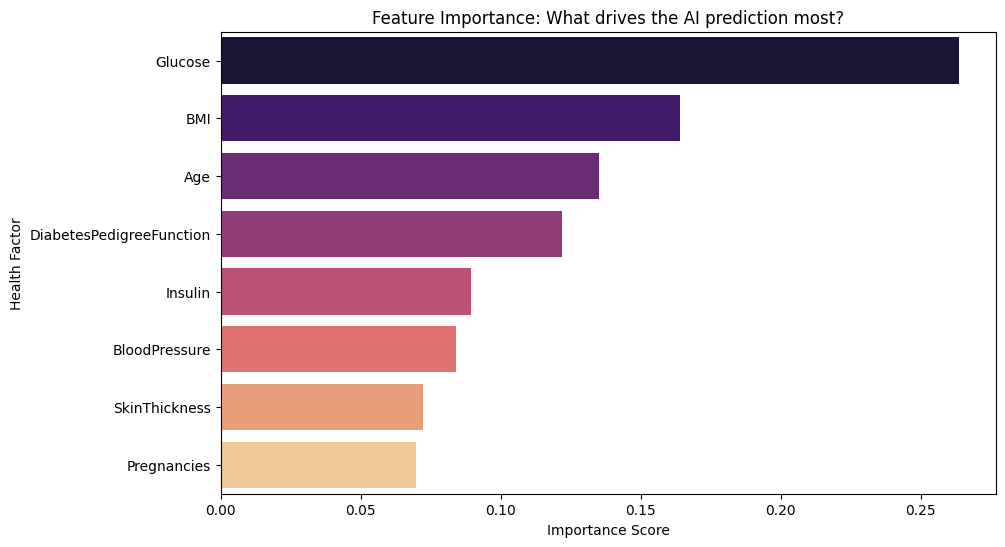

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# -----------------------------------------
# ANALYSIS: Which Health Factors Matter Most?
# -----------------------------------------

# 1. Ask the model for its internal scoring
importance_scores = model.feature_importances_

# 2. Create a clean table matching the scores to the column names
importance_df = pd.DataFrame({
    'Feature': X.columns, 
    'Importance': importance_scores
}).sort_values(by='Importance', ascending=False)

# 3. Draw a beautiful bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='magma')
plt.title('Feature Importance: What drives the AI prediction most?')
plt.xlabel('Importance Score')
plt.ylabel('Health Factor')
plt.show()

In [9]:
# -----------------------------------------
# LIVE APP: Interactive Patient Diagnosis
# -----------------------------------------
import ipywidgets as widgets
from IPython.display import display
import pandas as pd

print("🩺 LIVE PATIENT DIAGNOSIS TOOL 🩺")
print("Adjust the sliders to enter a new patient's vitals:\n")

# 1. Create interactive sliders for all 8 health factors
preg = widgets.IntSlider(value=1, min=0, max=15, description='Pregnancies:')
glucose = widgets.IntSlider(value=120, min=0, max=200, description='Glucose:')
bp = widgets.IntSlider(value=70, min=0, max=130, description='BP (Diastolic):')
skin = widgets.IntSlider(value=20, min=0, max=100, description='Skin Thick:')
insulin = widgets.IntSlider(value=79, min=0, max=900, description='Insulin:')
bmi = widgets.FloatSlider(value=25.0, min=0.0, max=70.0, description='BMI:')
dpf = widgets.FloatSlider(value=0.5, min=0.0, max=2.5, description='Pedigree:')
age = widgets.IntSlider(value=33, min=21, max=100, description='Age:')

# 2. Create a shiny predict button
button = widgets.Button(description="Predict Risk", button_style='success', icon='heartbeat')
output = widgets.Output()

# 3. Define what happens when the button is clicked
def on_button_clicked(b):
    with output:
        output.clear_output()
        
        # Package the slider values into the exact format the AI expects
        patient_data = pd.DataFrame([[
            preg.value, glucose.value, bp.value, skin.value, 
            insulin.value, bmi.value, dpf.value, age.value
        ]], columns=X.columns)
        
        # Ask our trained Random Forest model to predict
        prediction = model.predict(patient_data)[0]
        probability = model.predict_proba(patient_data)[0]
        
        # Print the results nicely
        print("\n" + "="*35)
        print("        AI DIAGNOSIS RESULT        ")
        print("="*35)
        
        if prediction == 1:
            print(f"⚠️ HIGH RISK for Diabetes Detected")
            print(f"Confidence Level: {probability[1]*100:.1f}%\n")
            print("Recommendation: Immediate medical consultation advised.")
        else:
            print(f"✅ LOW RISK for Diabetes Detected")
            print(f"Confidence Level: {probability[0]*100:.1f}%\n")
            print("Recommendation: Maintain a healthy lifestyle and diet.")

# Link the button to our function
button.on_click(on_button_clicked)

# 4. Display the whole dashboard on the screen
display(preg, glucose, bp, skin, insulin, bmi, dpf, age, button, output)

🩺 LIVE PATIENT DIAGNOSIS TOOL 🩺
Adjust the sliders to enter a new patient's vitals:



IntSlider(value=1, description='Pregnancies:', max=15)

IntSlider(value=120, description='Glucose:', max=200)

IntSlider(value=70, description='BP (Diastolic):', max=130)

IntSlider(value=20, description='Skin Thick:')

IntSlider(value=79, description='Insulin:', max=900)

FloatSlider(value=25.0, description='BMI:', max=70.0)

FloatSlider(value=0.5, description='Pedigree:', max=2.5)

IntSlider(value=33, description='Age:', min=21)

Button(button_style='success', description='Predict Risk', icon='heartbeat', style=ButtonStyle())

Output()

In [10]:
import joblib
import os

# 1. Create a folder to save our models if it doesn't exist yet
os.makedirs('../models', exist_ok=True)

# 2. Save our trained Random Forest model to a file
joblib.dump(model, '../models/diabetes_rf_model.pkl')

print("💾 SUCCESS: AI Brain saved as 'diabetes_rf_model.pkl'")
print("You can now load this file in any other Python script without retraining!")

💾 SUCCESS: AI Brain saved as 'diabetes_rf_model.pkl'
You can now load this file in any other Python script without retraining!
